In [1]:
import torch
import numpy as np
import torch.optim as optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from models.nn import *
from models.utils import *
from models.bmi import *
from models.aemi import *

In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
np.random.seed(0)
torch.manual_seed(0)

In [3]:
repeat = 40
n_classes = 2

In [4]:
X = np.arange(n_classes).repeat(repeat).reshape(-1,1).astype(np.float32)
Y = np.arange(n_classes).repeat(repeat).reshape(-1,1).astype(np.float32)
X += np.random.rand(repeat*n_classes, 1)
Y += np.random.rand(repeat*n_classes, 1)

In [5]:
X, Y = torch.tensor(X, dtype=torch.float32).to(device), torch.tensor(Y, dtype=torch.float32).to(device)
XY = torch.cat((X,Y), dim=1)

In [6]:
ae_model = AECross(1,1,60,1,1).to(device)
# load the model
ae_model.load_state_dict(torch.load('./checkpoints/aemi_demo.pt'))

<All keys matched successfully>

In [10]:
with torch.no_grad():
    Zx = ae_model.x_encoder(X)
    Zy = ae_model.y_encoder(Y)

In [28]:
mine = MINE(3,3,2).to(device)

In [29]:
mi_est = train_estimator(mine, Zx, Zy, bs=20, lr=1e-4, iters=40000)

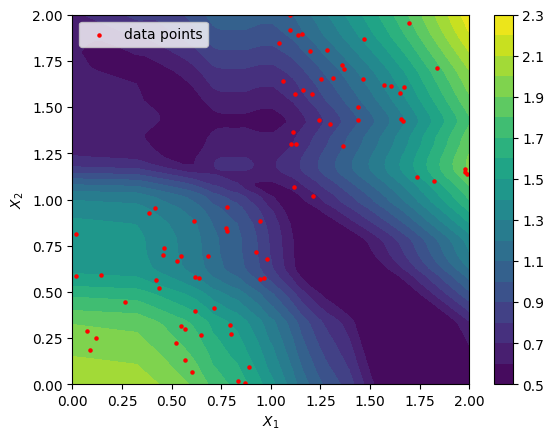

In [23]:
# draw a heatmap of the neural network

x = np.linspace(0, 2, 100)
y = np.linspace(0, 2, 100)
code_x = ae_model.x_encoder(torch.tensor(x.reshape(-1,1), dtype=torch.float32).to(device))
code_y = ae_model.y_encoder(torch.tensor(y.reshape(-1,1), dtype=torch.float32).to(device))

x, y = np.meshgrid(x, y)
Z = np.zeros_like(x)
for i in range(x.shape[0]):
    for j in range(x.shape[1]):
        Z[i,j] = mine.F_func(torch.cat([code_x[i], code_y[j]], dim=-1)).item()

plt.contourf(x, y, Z, 20)
plt.colorbar();
plt.scatter(X.cpu(), Y.cpu(), c='red', s=5, label='data points')
plt.xlabel('$X_1$')
plt.ylabel('$X_2$')
plt.legend()
# plt.scatter(center_x, center_y, c='red', s=20, label='centers')
plt.savefig('./figs/heatmap_demo_aemi.png')

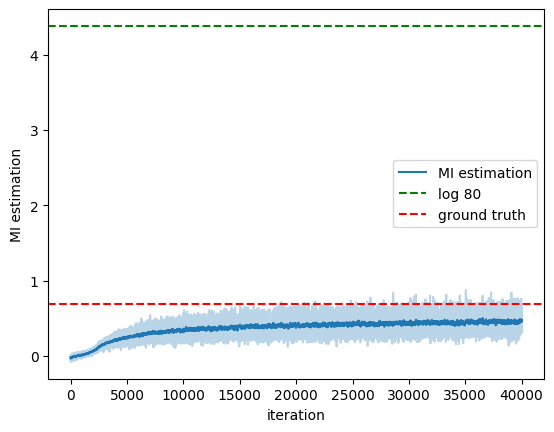

In [30]:
import pandas as pd
import math
EMA_SPAN = 50
p1 = plt.plot(mi_est, alpha=0.3)[0]
mis_smooth = pd.Series(mi_est).ewm(span=EMA_SPAN).mean()
plt.plot(mis_smooth, c=p1.get_color(), label=f'MI estimation')
plt.axhline(math.log(XY.shape[0]), c='g', ls='--', label=f'log {XY.shape[0]}')
plt.axhline(math.log(n_classes), c='r', ls='--', label='ground truth')
plt.xlabel('iteration')
plt.ylabel('MI estimation')
plt.legend()
# plt.legend(['raw', 'MI EMA'])
# plt.savefig(f'./figs/mi_est_label{test_labels}.png')
plt.show()